# Ejemplo Python - Pingüinos
---

## Descripción del dataset

* Origen: Proyecto Palmer Station LTER (Long Term Ecological Research) en la Antártida
* Observaciones: ~344 registros de pingüinos
* Variables:
    * species (factor): especie del pingüino (Adelie, Chinstrap, Gentoo)
    * island (factor): isla donde se observó (Biscoe, Dream, Torgersen)
    * bill_length_mm (numérica): longitud del pico en mm.
    * bill_depth_mm (numérica): profundidad del pico en mm.
    * flipper_length_mm (numérica): longitud de la aleta en mm.
    * body_mass_g (numérica): masa corporal en gramos
    * sex (factor): sexo del pingüino
    * year (entero): año de la medición

## Objetivo del dataset

* Principal: estudiar características morfológicas y ecológicas de pingüinos en distintas especies e islas
* En análisis de datos: se usa para:
    * Clasificación: predecir la especie a partir de medidas físicas
    * Exploración: relaciones entre tamaño del pico, masa corporal y hábitat
    * Visualización: ejemplos de gráficos multivariados

In [4]:
# Instalar y cargar paquetes
install.packages(c("palmerpenguins", "randomForest", "caret", "ggplot2"))
library(palmerpenguins)
library(randomForest)
library(caret)
library(ggplot2)


The downloaded binary packages are in
	/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T//RtmpNRuwCf/downloaded_packages


## 1. Cargar datos

In [24]:
data("penguins")

In [25]:
penguins <- na.omit(penguins)  # eliminar NA

## 2. Análisis exploratorio

In [26]:
summary(penguins)

      species          island    bill_length_mm  bill_depth_mm  
 Adelie   :146   Biscoe   :163   Min.   :32.10   Min.   :13.10  
 Chinstrap: 68   Dream    :123   1st Qu.:39.50   1st Qu.:15.60  
 Gentoo   :119   Torgersen: 47   Median :44.50   Median :17.30  
                                 Mean   :43.99   Mean   :17.16  
                                 3rd Qu.:48.60   3rd Qu.:18.70  
                                 Max.   :59.60   Max.   :21.50  
 flipper_length_mm  body_mass_g       sex           year     
 Min.   :172       Min.   :2700   female:165   Min.   :2007  
 1st Qu.:190       1st Qu.:3550   male  :168   1st Qu.:2007  
 Median :197       Median :4050                Median :2008  
 Mean   :201       Mean   :4207                Mean   :2008  
 3rd Qu.:213       3rd Qu.:4775                3rd Qu.:2009  
 Max.   :231       Max.   :6300                Max.   :2009  

In [27]:
table(penguins$species)


   Adelie Chinstrap    Gentoo 
      146        68       119 

In [28]:
str(penguins)

tibble [333 × 8] (S3: tbl_df/tbl/data.frame)
 $ species          : Factor w/ 3 levels "Adelie","Chinstrap",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ island           : Factor w/ 3 levels "Biscoe","Dream",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ bill_length_mm   : num [1:333] 39.1 39.5 40.3 36.7 39.3 38.9 39.2 41.1 38.6 34.6 ...
 $ bill_depth_mm    : num [1:333] 18.7 17.4 18 19.3 20.6 17.8 19.6 17.6 21.2 21.1 ...
 $ flipper_length_mm: int [1:333] 181 186 195 193 190 181 195 182 191 198 ...
 $ body_mass_g      : int [1:333] 3750 3800 3250 3450 3650 3625 4675 3200 3800 4400 ...
 $ sex              : Factor w/ 2 levels "female","male": 2 1 1 1 2 1 2 1 2 2 ...
 $ year             : int [1:333] 2007 2007 2007 2007 2007 2007 2007 2007 2007 2007 ...
 - attr(*, "na.action")= 'omit' Named int [1:11] 4 9 10 11 12 48 179 219 257 269 ...
  ..- attr(*, "names")= chr [1:11] "4" "9" "10" "11" ...


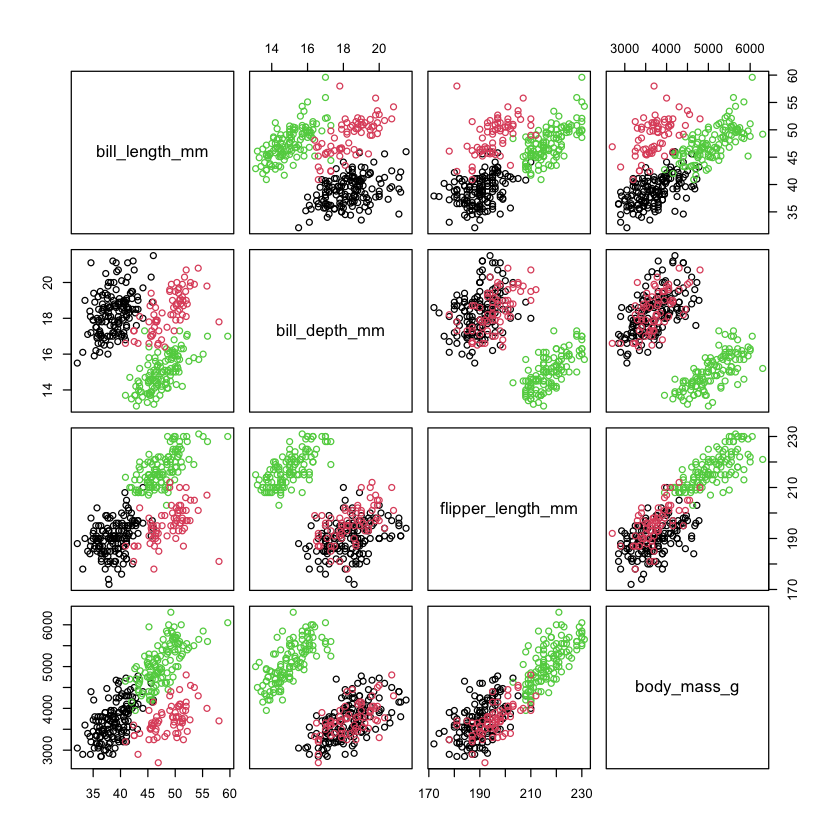

In [29]:
pairs(penguins[, c("bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g")],
      col = as.factor(penguins$species))

## 3. Preparar datos

In [30]:
set.seed(123)
trainIndex <- createDataPartition(penguins$species, p = 0.7, list = FALSE)
trainData <- penguins[trainIndex, ]
testData <- penguins[-trainIndex, ]

## 4. Ajustar modelo Random Forest básico

In [31]:
modelo_rf <- randomForest(species ~ bill_length_mm + bill_depth_mm + flipper_length_mm + body_mass_g,
                          data = trainData, 
                          ntree = 100, 
                          mtry = 2, 
                          importance = TRUE)
modelo_rf


Call:
 randomForest(formula = species ~ bill_length_mm + bill_depth_mm +      flipper_length_mm + body_mass_g, data = trainData, ntree = 100,      mtry = 2, importance = TRUE) 
               Type of random forest: classification
                     Number of trees: 100
No. of variables tried at each split: 2

        OOB estimate of  error rate: 4.26%
Confusion matrix:
          Adelie Chinstrap Gentoo class.error
Adelie        99         3      1  0.03883495
Chinstrap      5        43      0  0.10416667
Gentoo         0         1     83  0.01190476

## 5. Optimización de hiperparámetros con caret

In [32]:
control <- trainControl(method = "cv", number = 5)
grid <- expand.grid(mtry = c(2, 3, 4))  # valores a probar

modelo_tuned <- train(species ~ bill_length_mm + bill_depth_mm + flipper_length_mm + body_mass_g,
                      data = trainData,
                      method = "rf",
                      trControl = control,
                      tuneGrid = grid,
                      ntree = 200)
modelo_tuned

Random Forest 

235 samples
  4 predictor
  3 classes: 'Adelie', 'Chinstrap', 'Gentoo' 

No pre-processing
Resampling: Cross-Validated (5 fold) 
Summary of sample sizes: 188, 188, 188, 187, 189 
Resampling results across tuning parameters:

  mtry  Accuracy   Kappa    
  2     0.9618794  0.9402381
  3     0.9575355  0.9335833
  4     0.9533688  0.9270222

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was mtry = 2.

In [21]:
# 6. Evaluar en test
predicciones <- predict(modelo_tuned, newdata = testData)
confusionMatrix(predicciones, testData$species)

Confusion Matrix and Statistics

           Reference
Prediction  Adelie Chinstrap Gentoo
  Adelie        42         0      0
  Chinstrap      1        20      0
  Gentoo         0         0     35

Overall Statistics
                                          
               Accuracy : 0.9898          
                 95% CI : (0.9445, 0.9997)
    No Information Rate : 0.4388          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.9841          
                                          
 Mcnemar's Test P-Value : NA              

Statistics by Class:

                     Class: Adelie Class: Chinstrap Class: Gentoo
Sensitivity                 0.9767           1.0000        1.0000
Specificity                 1.0000           0.9872        1.0000
Pos Pred Value              1.0000           0.9524        1.0000
Neg Pred Value              0.9821           1.0000        1.0000
Prevalence                  0.4388        

## 7. Importancia de variables

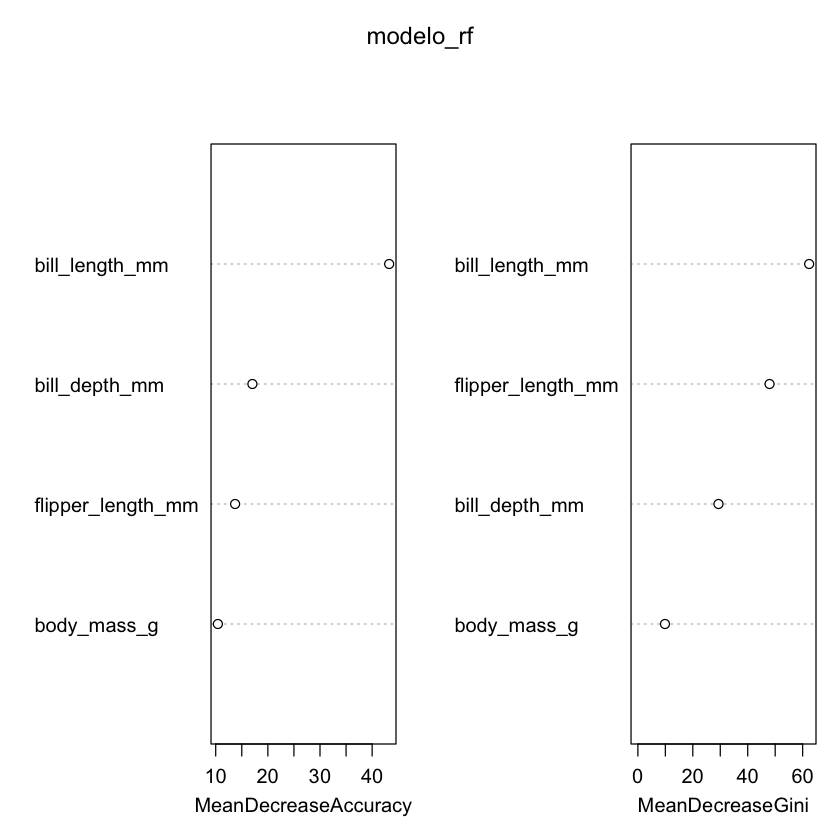

In [33]:
varImpPlot(modelo_rf)